# 03 — Deep Learning: Feed-Forward Neural Network (PyTorch)
**CodeCraft · Early Metabolic Risk Detection · NHANES 2017–2018**

> ⚠️ **Research/educational use only. Not a diagnosis or medical advice.**
> The data are **cross-sectional**: results describe classification *within this survey cycle*, **not** prediction of future disease.
> All metrics are **unweighted** (survey weights are not available). No claim is made about which model family (classical ML, deep learning, quantum ML) is better; only real runs from this notebook are reported.

**Task:** binary classification, positive class = *Elevated Risk* (HbA1c 5.7 % to < 6.5 %, label 1) vs *Normal* (< 5.7 %, label 0).

## How to run
- **Needed in Drive** (`MyDrive/CodeCraft/`): `train.csv`, `validation.csv`, `test.csv`, `split_manifest.json`, and **`results/shared_feature_set.json` created by `02_ml_model.ipynb`** (run order 02 → 03 → 04 → 05).
- *Runtime → Run all* on a fresh Colab runtime. **CPU is enough**; a GPU is used automatically if present (the backend is printed). Expected runtime: roughly 5–15 minutes on CPU (8-config search + 5 seeds + 1 supplementary run).
- **Resumable:** completed seed results are skipped on re-run (and the hyper-parameter search is reused) if the split, features and frozen config are unchanged. Everything is written under `MyDrive/CodeCraft/results/` (`dl/`, `predictions/`). Prediction CSVs are private working files, never part of an exported report.

## Section 1 — Setup, helpers, data loading, TC-06 test, shared feature set
Install only what is missing, mount Drive, define the common helper code (identical in every notebook), load the fixed splits (never re-split), run the TC-06 unit test, learn feature pruning on **train only**, and load the shared reduced feature set (its `split_hash` must match the current split files).

In [1]:
import importlib, subprocess, sys
for mod, pkg in [('torch', 'torch'), ('sklearn', 'scikit-learn'), ('pandas', 'pandas'), ('numpy', 'numpy'),
                 ('matplotlib', 'matplotlib'), ('joblib', 'joblib'), ('scipy', 'scipy')]:
    try:
        importlib.import_module(mod)
    except ImportError:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', pkg], check=True)
print('[VERIFIED] required packages available')

[VERIFIED] required packages available


In [2]:
# ===== COMMON HELPER CODE (identical in every notebook) =====
import numpy as np, pandas as pd, json, os, time, hashlib, resource, platform, sys
from pathlib import Path
from sklearn.metrics import roc_auc_score, confusion_matrix, roc_curve
from google.colab import drive
drive.mount('/content/drive')
BASE_DIR = Path('/content/drive/MyDrive/CodeCraft')
SEED = 42
DATASET_VERSION = 'nhanes-2017-2018-v1'
WARNING_TEXT = 'Research/educational use only. Not a diagnosis or medical advice.'

def file_sha256(paths):
    h = hashlib.sha256()
    for p in paths: h.update(Path(p).read_bytes())
    return h.hexdigest()

def write_json_atomic(obj, path):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_suffix(path.suffix + '.tmp')
    tmp.write_text(json.dumps(obj, indent=2, default=str)); os.replace(tmp, path)

def peak_memory_mb():
    return resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024.0

def compute_metrics(y_true, y_prob, thr):
    y_true = np.asarray(y_true).astype(int); y_pred = (np.asarray(y_prob) >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    div = lambda a, b: float(a / b) if b > 0 else None
    prec, sens, spec = div(tp, tp + fp), div(tp, tp + fn), div(tn, tn + fp)
    f1 = div(2 * prec * sens, prec + sens) if (prec is not None and sens is not None) else None
    auc = float(roc_auc_score(y_true, y_prob)) if len(np.unique(y_true)) == 2 else None
    return {'accuracy': float((tp + tn) / len(y_true)), 'precision': prec, 'sensitivity': sens,
            'specificity': spec, 'f1': f1, 'roc_auc': auc,
            'confusion': [[int(tn), int(fp)], [int(fn), int(tp)]]}  # [[TN,FP],[FN,TP]]

def pick_threshold(y_val, p_val, min_spec=0.70):
    fpr, tpr, thr = roc_curve(y_val, p_val)
    ok = np.where(((1 - fpr) >= min_spec) & np.isfinite(thr))[0]
    if len(ok) == 0: return 0.5, False
    return float(thr[ok[np.argmax(tpr[ok])]]), True

def bootstrap_ci(y_true, y_prob, thr, n=1000, seed=42):
    rng = np.random.default_rng(seed); y_true = np.asarray(y_true); y_prob = np.asarray(y_prob)
    keys = ['accuracy', 'precision', 'sensitivity', 'specificity', 'f1', 'roc_auc']
    out = {k: [] for k in keys}
    for _ in range(n):
        i = rng.integers(0, len(y_true), len(y_true)); m = compute_metrics(y_true[i], y_prob[i], thr)
        for k in keys:
            if m[k] is not None: out[k].append(m[k])
    return {k: ([float(np.percentile(v, 2.5)), float(np.percentile(v, 97.5))] if v else None) for k, v in out.items()}

def evaluate_run(y_val, p_val, y_test, p_test):
    thr, found = pick_threshold(y_val, p_val)
    return {'threshold': thr, 'threshold_found': found,
            'metrics_at_threshold': compute_metrics(y_test, p_test, thr),
            'metrics_at_0.5': compute_metrics(y_test, p_test, 0.5),
            'ci95': bootstrap_ci(y_test, p_test, thr),
            'test_n': int(len(y_test)), 'test_prevalence': float(np.mean(y_test))}

Mounted at /content/drive


In [3]:
import random, tempfile, shutil, numbers
import matplotlib, scipy, sklearn, joblib
import matplotlib.pyplot as plt
os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')   # needed for deterministic CUDA matmuls; must be set before CUDA init
import torch, torch.nn as nn

# ---- Backend: GPU automatically if available, otherwise CPU (never fails) ----
def pick_device():
    if torch.cuda.is_available():
        try:
            _ = (torch.zeros(1, device='cuda') + 1).item()
            return torch.device('cuda')
        except Exception as e:
            print('[NOTICE] CUDA reported but not usable; falling back to CPU:', str(e)[:120])
    return torch.device('cpu')
DEVICE = pick_device()
BACKEND = 'GPU' if DEVICE.type == 'cuda' else 'CPU'
DEVICE_NAME = torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else f'CPU ({platform.processor() or platform.machine()})'
try:
    torch.use_deterministic_algorithms(True, warn_only=True)   # warn (not fail) if an op has no deterministic version
    torch.backends.cudnn.deterministic = True; torch.backends.cudnn.benchmark = False
    DETERMINISM = 'torch.use_deterministic_algorithms(True, warn_only=True); cudnn.deterministic=True'
except Exception as e:
    DETERMINISM = f'not fully enabled ({str(e)[:80]})'

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
set_seed(SEED)

RESULTS_DIR = BASE_DIR / 'results'
DL_DIR, PRED_DIR, FIG_DIR = RESULTS_DIR / 'dl', RESULTS_DIR / 'predictions', RESULTS_DIR / 'dl' / 'figures'
for d in [RESULTS_DIR, DL_DIR, PRED_DIR, FIG_DIR, RESULTS_DIR / 'ml', RESULTS_DIR / 'qml']:
    d.mkdir(parents=True, exist_ok=True)

VERSIONS = {'python': sys.version.split()[0], 'numpy': np.__version__, 'pandas': pd.__version__,
            'scikit-learn': sklearn.__version__, 'scipy': scipy.__version__, 'matplotlib': matplotlib.__version__,
            'joblib': joblib.__version__, 'torch': torch.__version__}
print('Library versions:', json.dumps(VERSIONS))
print(f'Backend: {BACKEND} | device: {DEVICE_NAME} | determinism: {DETERMINISM}')
print('Base seed:', SEED, '| Platform:', platform.platform())
assert BASE_DIR.exists(), 'BASE_DIR not found - is Google Drive mounted and the CodeCraft folder present?'
print('[VERIFIED] Drive mounted; results folders ready under', RESULTS_DIR)

Library versions: {"python": "3.13.16", "numpy": "2.1.3", "pandas": "2.2.3", "scikit-learn": "1.6.1", "scipy": "1.16.3", "matplotlib": "3.10.0", "joblib": "1.6.0", "torch": "2.11.0+cpu"}
Backend: CPU | device: CPU (x86_64) | determinism: torch.use_deterministic_algorithms(True, warn_only=True); cudnn.deterministic=True
Base seed: 42 | Platform: Linux-6.6.122+-x86_64-with-glibc2.39
[VERIFIED] Drive mounted; results folders ready under /content/drive/MyDrive/CodeCraft/results


In [4]:
# ---- Load the three fixed splits (never re-split) ----
TARGET, POSITIVE, NEGATIVE = 'risk_label', 'Elevated Risk', 'Normal'
FORBIDDEN = ['SEQN', 'LBXGH', 'WTINT2YR', 'WTMEC2YR', 'SDMVPSU', 'SDMVSTRA']
PATHS = {s: BASE_DIR / f'{s}.csv' for s in ['train', 'validation', 'test']}
missing_files = [str(p) for p in PATHS.values() if not p.exists()]
if missing_files:
    raise FileNotFoundError('Missing split file(s) in Drive: ' + ', '.join(missing_files))

train_df, val_df, test_df = (pd.read_csv(PATHS[s]) for s in ['train', 'validation', 'test'])
for name, df in [('train', train_df), ('validation', val_df), ('test', test_df)]:
    assert TARGET in df.columns, f'{name}: column {TARGET!r} missing'
    assert not df.columns.duplicated().any(), f'{name}: duplicated column names'
    bad = [c for c in df.columns if c.upper() in FORBIDDEN]
    assert not bad, f'{name}: forbidden columns present: {bad}'
    assert df[TARGET].notna().all(), f'{name}: missing labels'
    assert set(df[TARGET].unique()) <= {NEGATIVE, POSITIVE}, f'{name}: unexpected labels {df[TARGET].unique()}'
    assert df[TARGET].nunique() == 2, f'{name}: both classes needed'
assert list(train_df.columns) == list(val_df.columns) == list(test_df.columns), 'Column mismatch between splits'

y_train, y_val, y_test = (((d[TARGET] == POSITIVE).astype(int)).to_numpy() for d in (train_df, val_df, test_df))
X_train, X_val, X_test = (d.drop(columns=[TARGET]) for d in (train_df, val_df, test_df))

split_hash = file_sha256([PATHS['train'], PATHS['validation'], PATHS['test']])
manifest_path = BASE_DIR / 'split_manifest.json'
print('split_manifest.json present:', manifest_path.exists())
print('split_hash:', split_hash)
for n, X, y in [('train', X_train, y_train), ('validation', X_val, y_val), ('test', X_test, y_test)]:
    print(f'{n:<10} rows={len(X):>6}  predictors={X.shape[1]}  prevalence(Elevated Risk)={y.mean():.3f}')
print('\nPredictor columns, dtypes and missingness in TRAIN (inspected at runtime):')
print(pd.DataFrame({'dtype': X_train.dtypes.astype(str), 'n_unique': X_train.nunique(dropna=True),
                    'pct_missing': (X_train.isna().mean() * 100).round(1)}).to_string())
print('[VERIFIED] splits loaded; no forbidden columns; identical columns across splits; both classes in every split')

split_manifest.json present: False
split_hash: d1419b74e6b90c7e93c051e0f497ba7d577c76b798214e33fa87a1b53ba2cdde
train      rows=  3160  predictors=52  prevalence(Elevated Risk)=0.347
validation rows=   677  predictors=52  prevalence(Elevated Risk)=0.346
test       rows=   678  predictors=52  prevalence(Elevated Risk)=0.347

Predictor columns, dtypes and missingness in TRAIN (inspected at runtime):
            dtype  n_unique  pct_missing
SDDSRVYR  float64         1          0.0
RIDSTATR  float64         1          0.0
RIAGENDR  float64         2          0.0
RIDAGEYR  float64        63          0.0
RIDRETH1  float64         5          0.0
RIDRETH3  float64         6          0.0
RIDEXMON  float64         2          0.0
RIDEXAGM  float64        24         95.0
DMQMILIZ  float64         3          0.0
DMQADFC   float64         2         91.2
DMDBORN4  float64         4          0.0
DMDCITZN  float64         4          0.1
DMDYRSUS  float64        11         71.3
DMDEDUC3  float64        

In [5]:
# ---- TC-06: compute_metrics vs scikit-learn on a fixed fixture ----
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
fx_y = np.array([0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 1, 0])
fx_p = np.array([0.10, 0.40, 0.35, 0.80, 0.65, 0.90, 0.20, 0.70, 0.55, 0.30, 0.45, 0.60])
m = compute_metrics(fx_y, fx_p, 0.5); fx_pred = (fx_p >= 0.5).astype(int)
expected = {'accuracy': accuracy_score(fx_y, fx_pred), 'precision': precision_score(fx_y, fx_pred),
            'sensitivity': recall_score(fx_y, fx_pred), 'specificity': recall_score(fx_y, fx_pred, pos_label=0),
            'f1': f1_score(fx_y, fx_pred), 'roc_auc': roc_auc_score(fx_y, fx_p)}
for k, v in expected.items():
    assert round(m[k], 4) == round(float(v), 4), f'TC-06 mismatch for {k}: {m[k]} vs {v}'
# Rule 4: metrics that cannot be computed must be None (never 0)
m0 = compute_metrics([0, 0, 0], [0.1, 0.2, 0.3], 0.5)
assert m0['sensitivity'] is None and m0['precision'] is None and m0['f1'] is None and m0['roc_auc'] is None
print('[PASSED] TC-06: compute_metrics matches scikit-learn to 4 decimals; undefined metrics return None')

[PASSED] TC-06: compute_metrics matches scikit-learn to 4 decimals; undefined metrics return None


In [6]:
# ---- Feature-column pruning: learned from TRAIN only ----
ADMIN_EXACT = {'BMDSTATS', 'RIDSTATR', 'SDDSRVYR', 'RIDEXMON'}

def learn_pruning(Xtr):
    dropped = {}
    for c in Xtr.columns:
        s = Xtr[c]; miss = s.isna().mean()
        if (c.startswith('BMI') and c != 'BMXBMI') or c in ADMIN_EXACT:
            dropped[c] = 'administrative / comment-code column'
        elif miss > 0.5:
            dropped[c] = f'>50% missing in train ({miss:.1%})'
        elif s.nunique(dropna=True) <= 1:
            dropped[c] = 'constant in train'
    return dropped

def classify_column(s):
    # Integer-coded columns with <=10 unique non-null values are categorical (even if stored as float)
    if (not pd.api.types.is_numeric_dtype(s)) or pd.api.types.is_bool_dtype(s):
        return 'categorical'
    v = s.dropna().to_numpy(dtype=float)
    if v.size and np.all(np.isfinite(v)) and np.all(v == np.round(v)) and len(np.unique(v)) <= 10:
        return 'categorical'
    return 'numeric'

DROPPED = learn_pruning(X_train)
KEPT_COLS = [c for c in X_train.columns if c not in DROPPED]
COL_TYPE = {c: classify_column(X_train[c]) for c in KEPT_COLS}
NUMERIC_COLS = [c for c in KEPT_COLS if COL_TYPE[c] == 'numeric']
CAT_COLS = [c for c in KEPT_COLS if COL_TYPE[c] == 'categorical']

print('Dropped columns (reason):')
print('\n'.join(f'  - {c}: {r}' for c, r in DROPPED.items()) if DROPPED else '  (none)')
print(f'\nKept {len(KEPT_COLS)} of {X_train.shape[1]} predictors: {len(NUMERIC_COLS)} numeric, {len(CAT_COLS)} categorical')
print(pd.DataFrame({'type': pd.Series(COL_TYPE), 'dtype': X_train[KEPT_COLS].dtypes.astype(str),
                    'n_unique': X_train[KEPT_COLS].nunique(dropna=True),
                    'pct_missing': (X_train[KEPT_COLS].isna().mean() * 100).round(1)}).to_string())
assert len(KEPT_COLS) > 0 and TARGET not in KEPT_COLS
assert not [c for c in KEPT_COLS if c.upper() in FORBIDDEN]
assert set(NUMERIC_COLS) | set(CAT_COLS) == set(KEPT_COLS) and not set(NUMERIC_COLS) & set(CAT_COLS)
print('[VERIFIED] pruning learned on train only; numeric/categorical partition is complete')

Dropped columns (reason):
  - SDDSRVYR: administrative / comment-code column
  - RIDSTATR: administrative / comment-code column
  - RIDEXMON: administrative / comment-code column
  - RIDEXAGM: >50% missing in train (95.0%)
  - DMQADFC: >50% missing in train (91.2%)
  - DMDYRSUS: >50% missing in train (71.3%)
  - DMDEDUC3: >50% missing in train (94.9%)
  - RIDEXPRG: >50% missing in train (78.0%)
  - DMDHSEDZ: >50% missing in train (51.1%)
  - BMDSTATS: administrative / comment-code column
  - BMIWT: administrative / comment-code column
  - BMIWAIST: administrative / comment-code column
  - BMIHIP: administrative / comment-code column

Kept 39 of 52 predictors: 15 numeric, 24 categorical
                 type    dtype  n_unique  pct_missing
RIAGENDR  categorical  float64         2          0.0
RIDAGEYR      numeric  float64        63          0.0
RIDRETH1  categorical  float64         5          0.0
RIDRETH3  categorical  float64         6          0.0
DMQMILIZ  categorical  float64     

In [7]:
# ---- Standard preprocessing (identical in all notebooks) ----
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

def make_preprocessor(numeric_cols, categorical_cols):
    transformers = []
    if numeric_cols:
        transformers.append(('num', Pipeline([('imp', SimpleImputer(strategy='median')),
                                              ('sc', StandardScaler())]), list(numeric_cols)))
    if categorical_cols:
        transformers.append(('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                                              ('oh', OneHotEncoder(handle_unknown='ignore', sparse_output=False,
                                                                   drop='if_binary'))]), list(categorical_cols)))
    return ColumnTransformer(transformers, remainder='drop', verbose_feature_names_out=False)

# sanity check on all kept columns: fit on TRAIN only, transform val/test
_pp = make_preprocessor(NUMERIC_COLS, CAT_COLS).fit(X_train[KEPT_COLS])
for n, X in [('train', X_train), ('validation', X_val), ('test', X_test)]:
    Z = _pp.transform(X[KEPT_COLS])
    assert np.isfinite(Z).all() and Z.shape[1] == len(_pp.get_feature_names_out())
print(f'[VERIFIED] preprocessing fitted on train only; {Z.shape[1]} transformed columns for the full pruned set')

[VERIFIED] preprocessing fitted on train only; 89 transformed columns for the full pruned set


In [8]:
# ---- Load the shared reduced feature set created by 02_ml_model.ipynb ----
SHARED_PATH = RESULTS_DIR / 'shared_feature_set.json'
if not SHARED_PATH.exists():
    raise FileNotFoundError(f'Run 02_ml_model.ipynb first: {SHARED_PATH} was not found.')
shared = json.loads(SHARED_PATH.read_text())
need = ['selected_features', 'numeric_features', 'categorical_features', 'transformed_dim', 'mi_ranking', 'split_hash', 'seed']
if [k for k in need if k not in shared]:
    raise ValueError('shared_feature_set.json is incomplete. Run 02_ml_model.ipynb first.')
if shared['split_hash'] != split_hash:
    raise RuntimeError('shared_feature_set.json was created for different split files (split_hash mismatch). Run 02_ml_model.ipynb first.')

MAIN_FEATURES = list(shared['selected_features'])
assert set(MAIN_FEATURES) <= set(KEPT_COLS), 'shared features not among the pruned train columns'
assert not [c for c in MAIN_FEATURES if c.upper() in FORBIDDEN]
assert set(shared['numeric_features']) == {c for c in MAIN_FEATURES if COL_TYPE[c] == 'numeric'}
assert set(shared['categorical_features']) == {c for c in MAIN_FEATURES if COL_TYPE[c] == 'categorical'}
_dim = len(make_preprocessor([c for c in MAIN_FEATURES if c in NUMERIC_COLS], [c for c in MAIN_FEATURES if c in CAT_COLS])
           .fit(X_train[MAIN_FEATURES]).get_feature_names_out())
assert _dim == shared['transformed_dim'] <= 8, f'transformed_dim mismatch: {_dim} vs {shared["transformed_dim"]}'
print('Shared features:', MAIN_FEATURES)
print(f'[VERIFIED] shared feature set loaded; split_hash matches; transformed_dim = {_dim} (<= 8)')

Shared features: ['RIDAGEYR', 'DMDHRAGZ', 'DMDHHSZE', 'BMXWAIST', 'BMXBMI']
[VERIFIED] shared feature set loaded; split_hash matches; transformed_dim = 8 (<= 8)


## Section 2 — MLP adapter
`Linear → ReLU → Dropout` blocks and one output logit. Loss: `BCEWithLogitsLoss(pos_weight = n_neg / n_pos)` computed on **train**. Optimiser: Adam (`weight_decay=1e-4`), batch size 128, up to 100 epochs, **early stopping (patience 10) on validation loss** with best weights restored. Preprocessing is fit on train inside the adapter and converted to `float32` tensors. Seeds are set for `random`, NumPy and torch; deterministic algorithms are requested where practical.

In [9]:
# DL_TORCH_CORE: all PyTorch-specific code lives in this cell
class MLP(nn.Module):
    def __init__(self, in_dim, hidden, dropout):
        super().__init__()
        layers, d = [], in_dim
        for h in hidden:
            layers += [nn.Linear(d, h), nn.ReLU(), nn.Dropout(dropout)]; d = h
        layers.append(nn.Linear(d, 1))                      # single output logit
        self.net = nn.Sequential(*layers)
    def forward(self, x):
        return self.net(x).squeeze(-1)

def train_mlp(Ztr, ytr, Zva, yva, cfg, seed, device):
    # Trains on TRAIN rows; early stopping on VALIDATION loss; restores the best weights. Test data never enters here.
    set_seed(seed)
    model = MLP(Ztr.shape[1], cfg['hidden'], cfg['dropout']).to(device)
    n_pos = int(np.sum(ytr)); n_neg = int(len(ytr) - n_pos); assert n_pos > 0 and n_neg > 0
    pos_weight_value = n_neg / n_pos
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([pos_weight_value], dtype=torch.float32, device=device))
    opt = torch.optim.Adam(model.parameters(), lr=cfg['lr'], weight_decay=cfg['weight_decay'])
    Xt = torch.from_numpy(np.ascontiguousarray(Ztr, dtype=np.float32)).to(device)
    yt = torch.from_numpy(np.asarray(ytr, dtype=np.float32)).to(device)
    Xv = torch.from_numpy(np.ascontiguousarray(Zva, dtype=np.float32)).to(device)
    yv = torch.from_numpy(np.asarray(yva, dtype=np.float32)).to(device)
    gen = torch.Generator(); gen.manual_seed(seed)           # CPU generator for batch shuffling
    best, best_epoch, best_state, bad = float('inf'), -1, None, 0
    tr_hist, va_hist, bs = [], [], cfg['batch_size']
    for epoch in range(cfg['max_epochs']):
        model.train(); perm = torch.randperm(len(Xt), generator=gen).to(device); run, cnt = 0.0, 0
        for i in range(0, len(perm), bs):
            idx = perm[i:i + bs]
            opt.zero_grad(set_to_none=True)
            loss = loss_fn(model(Xt[idx]), yt[idx]); loss.backward(); opt.step()
            run += loss.item() * len(idx); cnt += len(idx)
        model.eval()
        with torch.no_grad():
            vloss = loss_fn(model(Xv), yv).item()
        tr_hist.append(run / cnt); va_hist.append(vloss)
        if vloss < best:
            best, best_epoch, bad = vloss, epoch, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= cfg['patience']: break
    model.load_state_dict(best_state); model.eval()
    hist = {'train_loss': tr_hist, 'val_loss': va_hist, 'best_epoch': int(best_epoch), 'epochs_run': len(tr_hist),
            'stopped_early': len(tr_hist) < cfg['max_epochs'], 'pos_weight': float(pos_weight_value)}
    return model, hist

def mlp_predict(model, Z, device):
    model.eval()
    with torch.no_grad():
        logits = model(torch.from_numpy(np.ascontiguousarray(Z, dtype=np.float32)).to(device))
    return torch.sigmoid(logits).cpu().numpy().astype(np.float64).reshape(-1)

def save_model_state(model, path):
    path = Path(path); tmp = path.with_suffix(path.suffix + '.tmp')
    torch.save({k: v.detach().cpu() for k, v in model.state_dict().items()}, tmp); os.replace(tmp, path)

def load_model_state(path, in_dim, cfg, device):
    m = MLP(in_dim, cfg['hidden'], cfg['dropout'])
    m.load_state_dict(torch.load(path, map_location='cpu', weights_only=True))
    return m.to(device).eval()
print('[VERIFIED] MLP, training loop (early stopping on validation loss) and prediction functions defined')

[VERIFIED] MLP, training loop (early stopping on validation loss) and prediction functions defined


In [10]:
fmt = lambda v, nd=3: 'n/a' if v is None else f'{v:.{nd}f}'
_iso_now = lambda: pd.Timestamp.now(tz='UTC').isoformat()
def json_roundtrip(o): return json.loads(json.dumps(o, default=str))

class MLPAdapter:
    # fit(X, y) / predict_proba(X) -> positive-class probability / describe() -> dict
    # X = DataFrame containing the feature columns. val_data=(X_val, y_val) is used ONLY for early stopping.
    def __init__(self, cfg, feature_cols, seed, val_data=None):
        self.cfg, self.feature_cols, self.seed, self.val_data = dict(cfg), list(feature_cols), int(seed), val_data
        self.numeric = [c for c in self.feature_cols if c in NUMERIC_COLS]
        self.categorical = [c for c in self.feature_cols if c in CAT_COLS]
        self.preprocessor_ = self.model_ = self.history_ = None
    def _z(self, X):
        return self.preprocessor_.transform(X[self.feature_cols]).astype(np.float32)
    def fit(self, X, y):
        assert self.val_data is not None, 'validation data needed for early stopping'
        Xv, yv = self.val_data
        self.preprocessor_ = make_preprocessor(self.numeric, self.categorical).fit(X[self.feature_cols])   # TRAIN only
        self.model_, self.history_ = train_mlp(self._z(X), np.asarray(y).astype(int), self._z(Xv), np.asarray(yv).astype(int),
                                               self.cfg, self.seed, DEVICE)
        return self
    def predict_proba(self, X):
        return mlp_predict(self.model_, self._z(X), DEVICE)
    def n_transformed(self):
        return int(len(self.preprocessor_.get_feature_names_out()))
    def describe(self):
        return {'family': 'dl', 'model_name': 'MLP', 'framework': 'PyTorch', 'hyperparameters': self.cfg, 'seed': self.seed,
                'input_features': self.feature_cols, 'n_transformed_features': self.n_transformed(),
                'best_epoch': None if self.history_ is None else self.history_['best_epoch'] + 1, 'positive_class': POSITIVE}
    def save_artifacts(self, directory, tag):
        directory = Path(directory)
        save_model_state(self.model_, directory / f'model_{tag}.pt')
        tmp = directory / f'preprocessor_{tag}.joblib.tmp'; joblib.dump(self.preprocessor_, tmp); os.replace(tmp, directory / f'preprocessor_{tag}.joblib')
        write_json_atomic({**self.history_, 'config': self.cfg, 'seed': self.seed, 'feature_set': self.feature_cols}, directory / f'history_{tag}.json')
    def load_artifacts(self, directory, tag):
        directory = Path(directory)
        self.preprocessor_ = joblib.load(directory / f'preprocessor_{tag}.joblib')
        self.model_ = load_model_state(directory / f'model_{tag}.pt', self.n_transformed(), self.cfg, DEVICE)
        self.history_ = json.loads((directory / f'history_{tag}.json').read_text()); return self

# ---- Run-result helpers (contract: results/<family>/run_<experiment>_seed<seed>.json) ----
def _common_fields(experiment, family, seed):
    return {'runId': f'{family}_{experiment}_seed{seed}', 'family': family, 'experiment': experiment, 'seed': int(seed),
            'timestamp': _iso_now(), 'dataset_version': DATASET_VERSION, 'split_hash': split_hash,
            'positive_class': POSITIVE, 'versions': VERSIONS, 'backend': BACKEND}

def _write_result(payload, results_dir, family, experiment, seed, preds=None):
    # Never overwrite an existing COMPLETED result with a FAILED one.
    path = Path(results_dir) / family / f'run_{experiment}_seed{seed}.json'
    if payload['status'] == 'failed' and path.exists():
        try: old = json.loads(path.read_text())
        except Exception: old = {}
        if old.get('status') == 'completed':
            print(f'[KEPT] existing completed result preserved: {path.name}'); return path, False
    if preds is not None:
        pp = Path(results_dir) / 'predictions' / f'{family}_{experiment}_seed{seed}.csv'
        pp.parent.mkdir(parents=True, exist_ok=True)
        tmp = pp.with_suffix('.csv.tmp'); preds.to_csv(tmp, index=False); os.replace(tmp, pp)
    write_json_atomic(payload, path)
    return path, True

def _failed_payload(experiment, seed, exc, t0, family='dl'):
    msg = f'{type(exc).__name__}: {" ".join(str(exc).split())[:300]}'      # readable, no stack trace
    return {**_common_fields(experiment, family, seed), 'model_name': None, 'status': 'failed', 'error': msg,
            'feature_set': None, 'n_transformed_features': None, 'config': {},
            'runtime_sec': round(time.time() - t0, 2), 'peak_memory_mb': round(peak_memory_mb(), 1)}

def safe_run(experiment, seed, builder, results_dir=None, family='dl'):
    # builder() -> dict(model_name, feature_set, n_transformed_features, config, evaluation, predictions)
    results_dir = Path(results_dir or RESULTS_DIR); t0 = time.time()
    try:
        out = builder()
        payload = {**_common_fields(experiment, family, seed), 'model_name': out['model_name'], 'status': 'completed', 'error': None,
                   'feature_set': out['feature_set'], 'n_transformed_features': out['n_transformed_features'], 'config': out['config'],
                   'runtime_sec': round(time.time() - t0, 2), 'peak_memory_mb': round(peak_memory_mb(), 1), **out['evaluation']}
        preds = out['predictions']
    except Exception as e:
        payload, preds = _failed_payload(experiment, seed, e, t0, family), None
        print(f'[FAILED] run {experiment} seed {seed}: {payload["error"]}')
    _write_result(payload, results_dir, family, experiment, seed, preds)
    return payload

RUNS = {}
def make_dl_builder(experiment, seed, feats, frozen, extra_config):
    def _builder():
        if DEVICE.type == 'cuda': torch.cuda.reset_peak_memory_stats()
        ad = MLPAdapter(frozen, feats, seed, (X_val, y_val)).fit(X_train, y_train)
        p_val, p_test = ad.predict_proba(X_val), ad.predict_proba(X_test)     # the ONE test scoring of this final model
        ev = evaluate_run(y_val, p_val, y_test, p_test)
        RUNS[(experiment, seed)] = {'adapter': ad}
        h = ad.history_
        cfg = {'model': 'MLP (PyTorch)', 'frozen_config': json_roundtrip(frozen),
               'architecture': 'Linear -> ReLU -> Dropout blocks, single output logit',
               'loss': 'BCEWithLogitsLoss(pos_weight = n_neg/n_pos on train)', 'pos_weight': h['pos_weight'],
               'optimizer': 'Adam(weight_decay=1e-4)', 'early_stopping': 'patience 10 on validation loss; best weights restored',
               'best_epoch': h['best_epoch'] + 1, 'epochs_run': h['epochs_run'], 'stopped_early': h['stopped_early'],
               'device': DEVICE_NAME, 'determinism': DETERMINISM,
               'gpu_peak_memory_mb': round(torch.cuda.max_memory_allocated() / 2**20, 1) if DEVICE.type == 'cuda' else None,
               'threshold_rule': 'max sensitivity on validation subject to specificity >= 0.70; applied once to test',
               'metrics_weighting': 'unweighted', **extra_config}
        return {'model_name': 'MLP', 'feature_set': list(feats), 'n_transformed_features': ad.n_transformed(), 'config': cfg,
                'evaluation': ev, 'predictions': pd.DataFrame({'row_pos': np.arange(len(y_test)), 'y_true': y_test, 'y_prob': p_test})}
    return _builder
print('[VERIFIED] adapter, failure-safe runner and result helpers defined')

[VERIFIED] adapter, failure-safe runner and result helpers defined


## Section 3 — Small hyper-parameter search (seed 42, validation ROC-AUC only)
Grid: hidden sizes `[(64,32), (128,64)]` × dropout `[0.1, 0.3]` × learning rate `[1e-3, 3e-3]` (8 configurations), each trained on train with early stopping on validation loss. The best configuration by **validation ROC-AUC** is frozen; the test set is not touched. If a matching search result is already saved it is reused.

In [11]:
SEARCH_PATH = DL_DIR / 'hparam_search_seed42.json'
BASE_CFG = {'batch_size': 128, 'max_epochs': 100, 'patience': 10, 'weight_decay': 1e-4}
GRID = {'hidden': [[64, 32], [128, 64]], 'dropout': [0.1, 0.3], 'lr': [1e-3, 3e-3]}
CONFIGS = [{**BASE_CFG, 'hidden': h, 'dropout': d, 'lr': lr} for h in GRID['hidden'] for d in GRID['dropout'] for lr in GRID['lr']]
FORCE_RESEARCH = False          # set True to ignore a saved search

saved = None
if SEARCH_PATH.exists() and not FORCE_RESEARCH:
    s = json.loads(SEARCH_PATH.read_text())
    if s.get('split_hash') == split_hash and s.get('feature_set') == MAIN_FEATURES and s.get('grid') == GRID and s.get('base_cfg') == json_roundtrip(BASE_CFG):
        saved = s
if saved is not None:
    rows = saved['rows']; print('[RESUMED] reusing saved hyper-parameter search:', SEARCH_PATH.name)
else:
    rows = []
    for cfg in CONFIGS:
        t0 = time.time()
        ad = MLPAdapter(cfg, MAIN_FEATURES, 42, (X_val, y_val)).fit(X_train, y_train)
        pv = ad.predict_proba(X_val); thr, found = pick_threshold(y_val, pv); mv = compute_metrics(y_val, pv, thr)
        rows.append({'config': json_roundtrip(cfg), 'val_auc': mv['roc_auc'], 'val_loss_best': float(min(ad.history_['val_loss'])),
                     'best_epoch': ad.history_['best_epoch'] + 1, 'epochs_run': ad.history_['epochs_run'],
                     'val_sens_at_spec>=0.70': mv['sensitivity'], 'val_specificity': mv['specificity'], 'sec': round(time.time() - t0, 1)})
        print(f"  hidden={cfg['hidden']} dropout={cfg['dropout']} lr={cfg['lr']:<6} -> val AUC={fmt(mv['roc_auc'], 4)} ({rows[-1]['sec']}s)")
assert all(r['val_auc'] is not None for r in rows)
sel_idx = max(range(len(rows)), key=lambda i: round(rows[i]['val_auc'], 6))      # ties -> first listed
FROZEN_CFG = json_roundtrip(rows[sel_idx]['config'])
if saved is None:
    write_json_atomic({'split_hash': split_hash, 'feature_set': MAIN_FEATURES, 'grid': GRID, 'base_cfg': json_roundtrip(BASE_CFG), 'seed': 42,
                       'rows': rows, 'selected_index': sel_idx, 'frozen_config': FROZEN_CFG, 'selection_rule': 'highest validation ROC-AUC',
                       'timestamp': _iso_now()}, SEARCH_PATH)
print('\nValidation table (seed 42):')
print(pd.DataFrame({'hidden': [str(r['config']['hidden']) for r in rows], 'dropout': [r['config']['dropout'] for r in rows],
                    'lr': [r['config']['lr'] for r in rows], 'VAL ROC-AUC': [fmt(r['val_auc'], 4) for r in rows],
                    'best val loss': [fmt(r['val_loss_best'], 4) for r in rows], 'best epoch': [r['best_epoch'] for r in rows],
                    'VAL sens @ spec>=0.70': [fmt(r['val_sens_at_spec>=0.70']) for r in rows],
                    'selected': ['<-- frozen' if i == sel_idx else '' for i in range(len(rows))]}).to_string(index=False))
print('\nFROZEN CONFIG:', json.dumps(FROZEN_CFG))
assert len(rows) == 8
print('[VERIFIED] 8 configurations compared on validation ROC-AUC only; best config frozen')

  hidden=[64, 32] dropout=0.1 lr=0.001  -> val AUC=0.7605 (1.4s)
  hidden=[64, 32] dropout=0.1 lr=0.003  -> val AUC=0.7611 (0.9s)
  hidden=[64, 32] dropout=0.3 lr=0.001  -> val AUC=0.7611 (1.7s)
  hidden=[64, 32] dropout=0.3 lr=0.003  -> val AUC=0.7596 (1.3s)
  hidden=[128, 64] dropout=0.1 lr=0.001  -> val AUC=0.7607 (1.8s)
  hidden=[128, 64] dropout=0.1 lr=0.003  -> val AUC=0.7608 (1.5s)
  hidden=[128, 64] dropout=0.3 lr=0.001  -> val AUC=0.7606 (1.4s)
  hidden=[128, 64] dropout=0.3 lr=0.003  -> val AUC=0.7609 (1.1s)

Validation table (seed 42):
   hidden  dropout    lr VAL ROC-AUC best val loss  best epoch VAL sens @ spec>=0.70   selected
 [64, 32]      0.1 0.001      0.7605        0.7564          13                 0.688           
 [64, 32]      0.1 0.003      0.7611        0.7572          14                 0.692           
 [64, 32]      0.3 0.001      0.7611        0.7570          25                 0.697 <-- frozen
 [64, 32]      0.3 0.003      0.7596        0.7577          12 

## Section 4 — Frozen config × 5 seeds (42–46)
For **each seed**: train on train (early stopping on validation loss), choose the threshold on **validation**, evaluate on **test once**, save `run_main_seed<seed>.json` and the predictions CSV. Seeds with an existing *completed* result (same split, features and frozen config) are skipped. Seed 42 also saves the model `state_dict`, preprocessor and training history under `results/dl/`. Peak memory is the process-wide peak so far (it can only grow within one session).

In [12]:
SEEDS = [42, 43, 44, 45, 46]
FROZEN_RT = json_roundtrip(FROZEN_CFG)

def artifacts_ok(tag): return all((DL_DIR / f).exists() for f in [f'model_{tag}.pt', f'preprocessor_{tag}.joblib', f'history_{tag}.json'])

def existing_completed(experiment, seed, feats, need_artifacts=False):
    p = DL_DIR / f'run_{experiment}_seed{seed}.json'
    if not p.exists(): return None
    try: r = json.loads(p.read_text())
    except Exception: return None
    ok = (r.get('status') == 'completed' and r.get('split_hash') == split_hash and r.get('feature_set') == list(feats)
          and r.get('config', {}).get('frozen_config') == FROZEN_RT and (PRED_DIR / f'dl_{experiment}_seed{seed}.csv').exists())
    if ok and need_artifacts and not artifacts_ok(f'{experiment}_seed{seed}'): ok = False
    return r if ok else None

main_runs = {}
for sd in SEEDS:
    r = existing_completed('main', sd, MAIN_FEATURES, need_artifacts=(sd == 42))
    if r is not None:
        print(f'[SKIPPED] seed {sd}: completed result already exists'); main_runs[sd] = r; continue
    r = safe_run('main', sd, make_dl_builder('main', sd, MAIN_FEATURES, FROZEN_CFG, {'feature_set_type': 'shared reduced feature set (results/shared_feature_set.json)'}))
    if r['status'] == 'completed':
        if sd == 42: RUNS[('main', 42)]['adapter'].save_artifacts(DL_DIR, 'main_seed42')
        main_runs[sd] = r
        m = r['metrics_at_threshold']
        print(f"[DONE] seed {sd}: best epoch {r['config']['best_epoch']}/{r['config']['epochs_run']}, thr={r['threshold']:.4f}, "
              f"sens={fmt(m['sensitivity'])}, spec={fmt(m['specificity'])}, AUC={fmt(m['roc_auc'])}, {r['runtime_sec']}s")

tbl = []
for sd in SEEDS:
    r = main_runs.get(sd)
    if r is None: tbl.append({'seed': sd, 'status': 'failed/missing'}); continue
    m, m5 = r['metrics_at_threshold'], r['metrics_at_0.5']
    tbl.append({'seed': sd, 'backend': r['backend'], 'thr (val)': round(r['threshold'], 4), 'sens': fmt(m['sensitivity']), 'spec': fmt(m['specificity']),
                'ROC-AUC': fmt(m['roc_auc']), 'acc': fmt(m['accuracy']), 'sens@0.5': fmt(m5['sensitivity']), 'spec@0.5': fmt(m5['specificity']),
                'runtime s': r['runtime_sec'], 'peak MB': r['peak_memory_mb']})
print('\nPer-seed TEST results (unweighted):'); print(pd.DataFrame(tbl).to_string(index=False))
assert len(main_runs) >= 1, 'no seed completed'
if len(main_runs) < len(SEEDS): print(f'[WARNING] only {len(main_runs)}/{len(SEEDS)} seeds completed - re-run this cell to retry the rest')
else: print('[VERIFIED] all 5 seeds completed and saved (run_main_seed42..46.json + predictions CSVs)')

[DONE] seed 42: best epoch 25/35, thr=0.5842, sens=0.668, spec=0.716, AUC=0.770, 3.71s
[DONE] seed 43: best epoch 20/30, thr=0.5806, sens=0.668, spec=0.718, AUC=0.768, 3.73s
[DONE] seed 44: best epoch 17/27, thr=0.5904, sens=0.655, spec=0.722, AUC=0.767, 4.94s
[DONE] seed 45: best epoch 22/32, thr=0.5796, sens=0.668, spec=0.713, AUC=0.768, 4.53s
[DONE] seed 46: best epoch 31/41, thr=0.5818, sens=0.647, spec=0.727, AUC=0.766, 6.38s

Per-seed TEST results (unweighted):
 seed backend  thr (val)  sens  spec ROC-AUC   acc sens@0.5 spec@0.5  runtime s  peak MB
   42     CPU     0.5842 0.668 0.716   0.770 0.699    0.791    0.614       3.71    521.1
   43     CPU     0.5806 0.668 0.718   0.768 0.701    0.779    0.625       3.73    521.5
   44     CPU     0.5904 0.655 0.722   0.767 0.699    0.796    0.607       4.94    521.5
   45     CPU     0.5796 0.668 0.713   0.768 0.698    0.787    0.623       4.53    521.6
   46     CPU     0.5818 0.647 0.727   0.766 0.699    0.796    0.623       6.38    

## Section 5 — Summary across seeds
Mean ± sample SD (ddof = 1) over the completed seeds, for threshold-based metrics (threshold chosen on validation per seed) and ROC-AUC; metrics at threshold 0.5 are reported separately. **The SD reflects seed variation only** (initialisation, batch order, dropout) on one fixed split and one fixed test set; it does not capture test-set sampling uncertainty (see the per-run bootstrap CIs in the JSON files).

In [13]:
loaded = {}
for sd in SEEDS:
    p = DL_DIR / f'run_main_seed{sd}.json'
    if p.exists():
        r = json.loads(p.read_text())
        if r.get('status') == 'completed' and r.get('split_hash') == split_hash: loaded[sd] = r
assert len(loaded) >= 1
assert all(r['feature_set'] == MAIN_FEATURES and r['config']['frozen_config'] == FROZEN_RT for r in loaded.values()), 'runs use different features/configs'
KEYS = ['sensitivity', 'specificity', 'precision', 'f1', 'accuracy', 'roc_auc']
def agg(vals):
    v = [x for x in vals if x is not None]
    if not v: return {'mean': None, 'sd': None, 'n': 0, 'values': vals}
    return {'mean': float(np.mean(v)), 'sd': float(np.std(v, ddof=1)) if len(v) > 1 else None, 'n': len(v), 'values': vals}
ms = lambda a: 'n/a' if a['mean'] is None else (f"{a['mean']:.3f} +/- {a['sd']:.3f}" if a['sd'] is not None else f"{a['mean']:.3f} (n=1)")
at_thr = {k: agg([loaded[s]['metrics_at_threshold'][k] for s in sorted(loaded)]) for k in KEYS}
at_05 = {k: agg([loaded[s]['metrics_at_0.5'][k] for s in sorted(loaded)]) for k in KEYS}
thr_agg = agg([loaded[s]['threshold'] for s in sorted(loaded)])
summary = {'family': 'dl', 'experiment': 'main', 'model_name': 'MLP', 'seeds': sorted(loaded), 'n_seeds': len(loaded),
           'frozen_config': FROZEN_RT, 'feature_set': MAIN_FEATURES, 'split_hash': split_hash, 'dataset_version': DATASET_VERSION,
           'positive_class': POSITIVE, 'threshold': thr_agg, 'metrics_at_threshold': at_thr, 'metrics_at_0.5': at_05,
           'runtime_sec': agg([loaded[s]['runtime_sec'] for s in sorted(loaded)]), 'backends': sorted({loaded[s]['backend'] for s in loaded}),
           'sd_note': 'SD (ddof=1) reflects seed variation only (init, batch order, dropout) on one fixed split and test set; metrics are unweighted.',
           'warning': WARNING_TEXT, 'timestamp': _iso_now()}
write_json_atomic(summary, DL_DIR / 'summary_main.json')

print(f"Mean +/- SD over seeds {sorted(loaded)} (TEST, unweighted); threshold chosen on validation per seed")
print(pd.DataFrame({'metric': KEYS, 'at val-chosen threshold': [ms(at_thr[k]) for k in KEYS], 'at threshold 0.5': [ms(at_05[k]) for k in KEYS]}).to_string(index=False))
print('mean validation-chosen threshold:', ms(thr_agg))
print('NOTE: SD reflects seed variation only (fixed split, fixed test set); it is not a confidence interval for generalisation.')
assert (DL_DIR / 'summary_main.json').exists()
print('[VERIFIED] summary_main.json saved')

Mean +/- SD over seeds [42, 43, 44, 45, 46] (TEST, unweighted); threshold chosen on validation per seed
     metric at val-chosen threshold at threshold 0.5
sensitivity         0.661 +/- 0.010  0.790 +/- 0.007
specificity         0.719 +/- 0.005  0.619 +/- 0.008
  precision         0.555 +/- 0.002  0.523 +/- 0.004
         f1         0.604 +/- 0.004  0.630 +/- 0.003
   accuracy         0.699 +/- 0.001  0.678 +/- 0.004
    roc_auc         0.768 +/- 0.002  0.768 +/- 0.002
mean validation-chosen threshold: 0.583 +/- 0.004
NOTE: SD reflects seed variation only (fixed split, fixed test set); it is not a confidence interval for generalisation.
[VERIFIED] summary_main.json saved


## Section 6 — Plots for seed 42
Training/validation loss curves (train loss is measured during training with dropout active; both use the class-weighted loss), plus ROC curve and confusion matrix from the saved seed-42 test predictions. Line styles, markers and printed numbers are used in addition to colour.

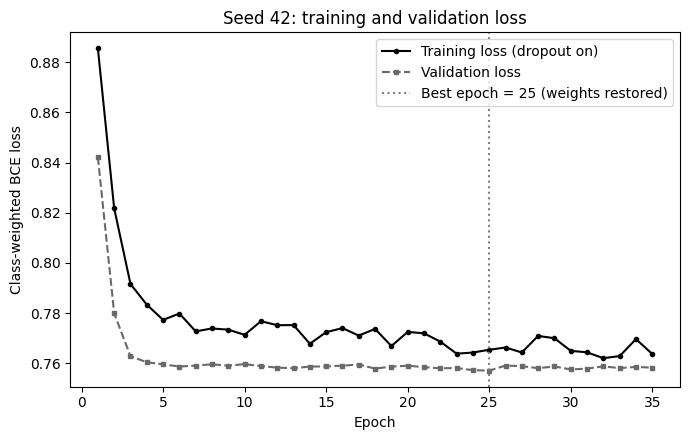

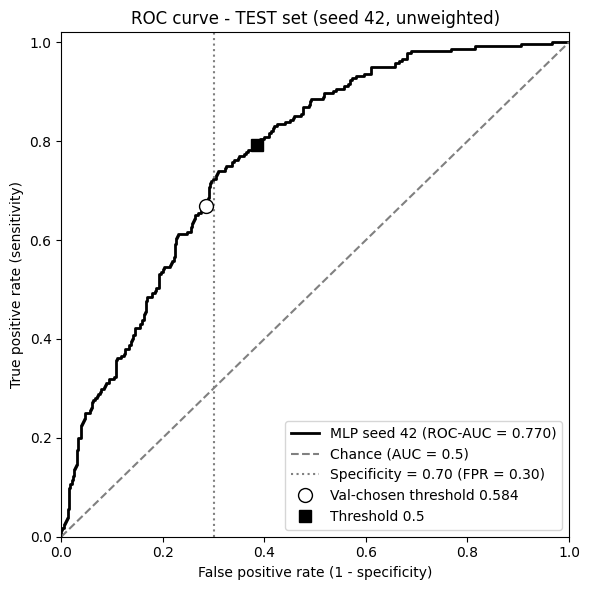

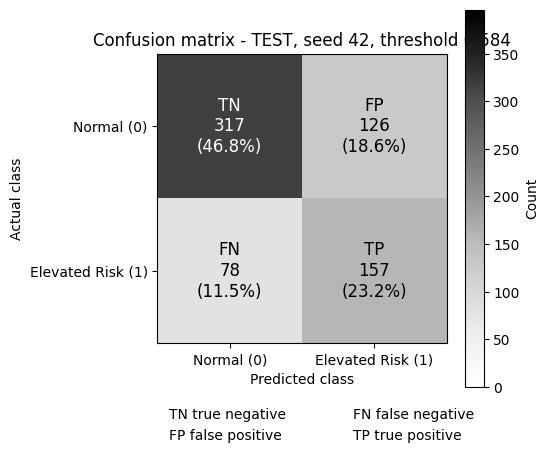

[VERIFIED] loss curves, ROC and confusion matrix for seed 42 created and saved under results/dl/figures


In [14]:
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
r42 = json.loads((DL_DIR / 'run_main_seed42.json').read_text()); assert r42['status'] == 'completed'
hist42 = json.loads((DL_DIR / 'history_main_seed42.json').read_text())
pred42 = pd.read_csv(PRED_DIR / 'dl_main_seed42.csv'); th, t5 = r42['metrics_at_threshold'], r42['metrics_at_0.5']
assert (pred42.y_true.to_numpy() == y_test).all()

ep = np.arange(1, len(hist42['train_loss']) + 1); be = hist42['best_epoch'] + 1
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(ep, hist42['train_loss'], linestyle='-', marker='o', markersize=3, color='black', label='Training loss (dropout on)')
ax.plot(ep, hist42['val_loss'], linestyle='--', marker='s', markersize=3, color='dimgray', label='Validation loss')
ax.axvline(be, linestyle=':', color='gray', label=f'Best epoch = {be} (weights restored)')
ax.set_xlabel('Epoch'); ax.set_ylabel('Class-weighted BCE loss'); ax.set_title('Seed 42: training and validation loss'); ax.legend(loc='upper right')
plt.tight_layout(); plt.savefig(FIG_DIR / 'loss_curves_seed42.png', dpi=150); plt.show()

fpr, tpr, _ = roc_curve(pred42.y_true, pred42.y_prob)
fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(fpr, tpr, linestyle='-', linewidth=2, color='black', label=f"MLP seed 42 (ROC-AUC = {fmt(th['roc_auc'])})")
ax.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Chance (AUC = 0.5)')
ax.axvline(0.30, linestyle=':', color='gray', label='Specificity = 0.70 (FPR = 0.30)')
if th['sensitivity'] is not None and th['specificity'] is not None:
    ax.plot(1 - th['specificity'], th['sensitivity'], marker='o', markersize=10, markerfacecolor='white', markeredgecolor='black', linestyle='None', label=f"Val-chosen threshold {r42['threshold']:.3f}")
if t5['sensitivity'] is not None and t5['specificity'] is not None:
    ax.plot(1 - t5['specificity'], t5['sensitivity'], marker='s', markersize=9, markerfacecolor='black', markeredgecolor='black', linestyle='None', label='Threshold 0.5')
ax.set_xlabel('False positive rate (1 - specificity)'); ax.set_ylabel('True positive rate (sensitivity)')
ax.set_title('ROC curve - TEST set (seed 42, unweighted)'); ax.legend(loc='lower right'); ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
plt.tight_layout(); plt.savefig(FIG_DIR / 'roc_seed42.png', dpi=150); plt.show()

cm = np.array(th['confusion']); tot = cm.sum()
fig, ax = plt.subplots(figsize=(5.5, 5)); im = ax.imshow(cm, cmap='Greys', vmin=0, vmax=cm.max() * 1.25)
lab = [['TN', 'FP'], ['FN', 'TP']]
for i in range(2):
    for j in range(2):
        ax.text(j, i, f'{lab[i][j]}\n{cm[i, j]}\n({cm[i, j] / tot:.1%})', ha='center', va='center', color='white' if cm[i, j] > cm.max() * 0.6 else 'black', fontsize=12)
ax.set_xticks([0, 1]); ax.set_xticklabels(['Normal (0)', 'Elevated Risk (1)']); ax.set_yticks([0, 1]); ax.set_yticklabels(['Normal (0)', 'Elevated Risk (1)'])
ax.set_xlabel('Predicted class'); ax.set_ylabel('Actual class'); ax.set_title(f"Confusion matrix - TEST, seed 42, threshold {r42['threshold']:.3f}")
plt.colorbar(im, ax=ax).set_label('Count')
ax.legend(handles=[Line2D([], [], linestyle='', label=t) for t in ['TN true negative', 'FP false positive', 'FN false negative', 'TP true positive']], loc='upper center', bbox_to_anchor=(0.5, -0.18), ncol=2, frameon=False)
plt.tight_layout(); plt.savefig(FIG_DIR / 'confusion_seed42.png', dpi=150); plt.show()
print('[VERIFIED] loss curves, ROC and confusion matrix for seed 42 created and saved under results/dl/figures')

## Section 7 — SUPPLEMENTARY: full pruned-feature run (seed 42 only)
Same frozen config and training procedure, but **all pruned features** instead of the shared reduced set (no re-tuning). Saved as `run_full_seed42.json`. **Supplementary only; not used in the headline comparison.**

In [15]:
full_run = safe_run('full', 42, make_dl_builder('full', 42, KEPT_COLS, FROZEN_CFG, {'supplementary': True,
        'label': 'SUPPLEMENTARY full pruned-feature run (seed 42 only, config frozen on the shared feature set); not used in the headline comparison',
        'feature_set_type': 'all pruned features'}))
assert full_run['status'] == 'completed', full_run['error']
fm = full_run['metrics_at_threshold']
print(f"[SUPPLEMENTARY] MLP, {len(KEPT_COLS)} features -> {full_run['n_transformed_features']} transformed columns, backend {full_run['backend']}, {full_run['runtime_sec']}s")
print(f"  thr={full_run['threshold']:.4f}  TEST sensitivity={fmt(fm['sensitivity'])}  specificity={fmt(fm['specificity'])}  ROC-AUC={fmt(fm['roc_auc'])}  accuracy={fmt(fm['accuracy'])}")
assert (DL_DIR / 'run_full_seed42.json').exists() and (PRED_DIR / 'dl_full_seed42.csv').exists()
print('[VERIFIED] run_full_seed42.json saved (supplementary)')

[SUPPLEMENTARY] MLP, 39 features -> 89 transformed columns, backend CPU, 4.04s
  thr=0.5938  TEST sensitivity=0.698  specificity=0.716  ROC-AUC=0.777  accuracy=0.709
[VERIFIED] run_full_seed42.json saved (supplementary)


## Section 8 — Single-record demo, failure-isolation test, summary
`predict_single_record` loads the **saved seed-42 `state_dict` and preprocessor** from `results/dl/`, validates every field **before** the model is called (invalid input returns a field-level error list and the model is not invoked). Output is a research score, not a diagnosis.

In [16]:
DEMO = MLPAdapter(FROZEN_CFG, MAIN_FEATURES, 42).load_artifacts(DL_DIR, 'main_seed42')
assert np.allclose(DEMO.predict_proba(X_test), pred42.y_prob.to_numpy(), atol=1e-4), 'reloaded model does not reproduce saved seed-42 predictions'
print('[VERIFIED] saved state_dict + preprocessor reproduce the seed-42 test probabilities')

SINGLE_NUM_RANGE = {c: (float(X_train[c].min()), float(X_train[c].max())) for c in MAIN_FEATURES if c in NUMERIC_COLS}
SINGLE_CAT_LEVELS = {c: set(X_train[c].dropna().unique().tolist()) for c in MAIN_FEATURES if c in CAT_COLS}
MAIN_THRESHOLD = r42['threshold']; _CALLS = {'n': 0}

def _score_record(df):
    _CALLS['n'] += 1
    return float(DEMO.predict_proba(df)[0])

def predict_single_record(feature_dict):
    # Required fields = shared feature set. Numeric: finite number inside observed train range +/- 50% of its span.
    # Categorical: must be a category code seen in train. Missing/None rejected. Model is NOT called if any error.
    errors = []
    if not isinstance(feature_dict, dict):
        return {'valid': False, 'errors': [{'field': '<input>', 'error': 'input must be a dict of field -> value'}]}
    for k in feature_dict:
        if str(k).upper() in FORBIDDEN: errors.append({'field': k, 'error': 'field is not allowed as a predictor'})
    for c in MAIN_FEATURES:
        if c not in feature_dict or feature_dict[c] is None:
            errors.append({'field': c, 'error': 'required field is missing'}); continue
        v = feature_dict[c]
        if c in SINGLE_NUM_RANGE:
            if isinstance(v, bool) or not isinstance(v, numbers.Real) or not np.isfinite(v):
                errors.append({'field': c, 'error': f'must be a finite number, got {v!r}'}); continue
            lo, hi = SINGLE_NUM_RANGE[c]; span = hi - lo
            if not (lo - 0.5 * span <= v <= hi + 0.5 * span):
                errors.append({'field': c, 'error': f'{v} outside plausible range [{lo - 0.5 * span:.4g}, {hi + 0.5 * span:.4g}]'})
        else:
            try: ok = v in SINGLE_CAT_LEVELS[c]
            except TypeError: ok = False
            if not ok: errors.append({'field': c, 'error': f'{v!r} is not a known category; allowed: {sorted(SINGLE_CAT_LEVELS[c])}'})
    if errors: return {'valid': False, 'errors': errors}
    score = _score_record(pd.DataFrame([{c: feature_dict[c] for c in MAIN_FEATURES}]))
    return {'model': 'MLP (PyTorch, seed 42)', 'score': score, 'label': POSITIVE if score >= MAIN_THRESHOLD else NEGATIVE,
            'threshold': MAIN_THRESHOLD, 'warning': WARNING_TEXT}

complete = X_val[MAIN_FEATURES].notna().all(axis=1); assert complete.any()
valid_rec = X_val.loc[complete.idxmax(), MAIN_FEATURES].to_dict()
print('Valid example input:  ', valid_rec)
b = _CALLS['n']; res_ok = predict_single_record(valid_rec); print('Result:', res_ok)
assert _CALLS['n'] == b + 1 and set(res_ok) == {'model', 'score', 'label', 'threshold', 'warning'} and 0 <= res_ok['score'] <= 1

bad_rec = dict(valid_rec); num_demo = next((c for c in MAIN_FEATURES if c in NUMERIC_COLS), None)
if num_demo: bad_rec[num_demo] = 'abc'
drop_demo = [c for c in MAIN_FEATURES if c != num_demo][:1] or [MAIN_FEATURES[0]]; bad_rec.pop(drop_demo[0], None)
print('\nInvalid example input:', bad_rec)
b = _CALLS['n']; res_bad = predict_single_record(bad_rec); print('Result:', json.dumps(res_bad, indent=1, default=str))
assert res_bad['valid'] is False and len(res_bad['errors']) >= 1 and _CALLS['n'] == b
print('[PASSED] valid record scored; invalid record rejected with field-level errors and the model was NOT called')

[VERIFIED] saved state_dict + preprocessor reproduce the seed-42 test probabilities
Valid example input:   {'RIDAGEYR': 21.0, 'DMDHRAGZ': 4.0, 'DMDHHSZE': 1.0, 'BMXWAIST': 67.3, 'BMXBMI': 21.3}
Result: {'model': 'MLP (PyTorch, seed 42)', 'score': 0.05260887369513512, 'label': 'Normal', 'threshold': 0.5841925144195557, 'warning': 'Research/educational use only. Not a diagnosis or medical advice.'}

Invalid example input: {'RIDAGEYR': 'abc', 'DMDHHSZE': 1.0, 'BMXWAIST': 67.3, 'BMXBMI': 21.3}
Result: {
 "valid": false,
 "errors": [
  {
   "field": "RIDAGEYR",
   "error": "must be a finite number, got 'abc'"
  },
  {
   "field": "DMDHRAGZ",
   "error": "required field is missing"
  }
 ]
}
[PASSED] valid record scored; invalid record rejected with field-level errors and the model was NOT called


In [17]:
# ---- Failure-isolation test: an injected failure must not damage earlier completed results ----
def _sha(p): return hashlib.sha256(Path(p).read_bytes()).hexdigest()
protected = (sorted(DL_DIR.glob('run_*_seed*.json')) + sorted(PRED_DIR.glob('dl_*_seed*.csv')) +
             [DL_DIR / 'summary_main.json', SEARCH_PATH, SHARED_PATH] + [DL_DIR / f for f in ['model_main_seed42.pt', 'preprocessor_main_seed42.joblib', 'history_main_seed42.json']])
before_hash = {str(p): _sha(p) for p in protected}
assert all(json.loads(p.read_text()).get('status') == 'completed' for p in DL_DIR.glob('run_*_seed*.json'))

def _boom(): raise RuntimeError('Injected failure for isolation test')
fail_out = safe_run('main', 42, _boom)                    # same target file as a completed run
assert fail_out['status'] == 'failed'
assert before_hash == {str(p): _sha(p) for p in protected}, 'a completed result file was modified by a failed run!'
assert json.loads((DL_DIR / 'run_main_seed42.json').read_text())['status'] == 'completed'

tmp_dir = Path(tempfile.mkdtemp()); safe_run('main', 42, _boom, results_dir=tmp_dir)
rec = json.loads((tmp_dir / 'dl' / 'run_main_seed42.json').read_text())
assert rec['status'] == 'failed' and 'Injected failure' in rec['error'] and 'Traceback' not in rec['error']
shutil.rmtree(tmp_dir)
print(f'[PASSED] failure isolation: {len(protected)} protected files unchanged; failed run recorded readably when no earlier result exists')

[FAILED] run main seed 42: RuntimeError: Injected failure for isolation test
[KEPT] existing completed result preserved: run_main_seed42.json
[FAILED] run main seed 42: RuntimeError: Injected failure for isolation test
[PASSED] failure isolation: 18 protected files unchanged; failed run recorded readably when no earlier result exists


In [18]:
# ---- Final summary (re-read from saved files) ----
S = json.loads((DL_DIR / 'summary_main.json').read_text()); r42 = json.loads((DL_DIR / 'run_main_seed42.json').read_text()); rf = json.loads((DL_DIR / 'run_full_seed42.json').read_text())
msd = lambda a: 'n/a' if a['mean'] is None else (f"{a['mean']:.3f} +/- {a['sd']:.3f}" if a['sd'] is not None else f"{a['mean']:.3f} (n=1)")
print('=' * 100); print('DEEP LEARNING (PyTorch MLP) - FINAL SUMMARY   [family: dl]'); print('=' * 100)
print(f"Backend: {', '.join(S['backends'])} | seeds: {S['seeds']} | frozen config: {json.dumps(S['frozen_config'])}")
print('\nHEADLINE (main, shared reduced feature set) - mean +/- SD over seeds (seed variation only), TEST, unweighted:')
for k in ['sensitivity', 'specificity', 'roc_auc', 'accuracy']: print(f"  {k:<12} @val-chosen thr: {msd(S['metrics_at_threshold'][k])}    @0.5: {msd(S['metrics_at_0.5'][k])}")
m = r42['metrics_at_threshold']; ci = r42['ci95']
print(f"\nSeed-42 run: thr={r42['threshold']:.4f} sensitivity={fmt(m['sensitivity'])} " + ('' if ci['sensitivity'] is None else f"[{ci['sensitivity'][0]:.3f}, {ci['sensitivity'][1]:.3f}] ") +
      f"specificity={fmt(m['specificity'])} ROC-AUC={fmt(m['roc_auc'])} (test n={r42['test_n']}, prevalence={r42['test_prevalence']:.3f})")
fm = rf['metrics_at_threshold']
print(f"SUPPLEMENTARY full-feature (seed 42, not in headline): sensitivity={fmt(fm['sensitivity'])} specificity={fmt(fm['specificity'])} ROC-AUC={fmt(fm['roc_auc'])}")
print('\nFiles: results/dl/run_main_seed42..46.json | run_full_seed42.json | summary_main.json | hparam_search_seed42.json | model_main_seed42.pt | preprocessor_main_seed42.joblib')
print('\nNotes: cross-sectional NHANES 2017-2018 classification, NOT prediction of future disease; metrics are UNWEIGHTED; the test set was used once per final model.')
print('No claim is made about which model family performs best; compare only after all families have been run on the same split/features.')
print(WARNING_TEXT)

DEEP LEARNING (PyTorch MLP) - FINAL SUMMARY   [family: dl]
Backend: CPU | seeds: [42, 43, 44, 45, 46] | frozen config: {"batch_size": 128, "max_epochs": 100, "patience": 10, "weight_decay": 0.0001, "hidden": [64, 32], "dropout": 0.3, "lr": 0.001}

HEADLINE (main, shared reduced feature set) - mean +/- SD over seeds (seed variation only), TEST, unweighted:
  sensitivity  @val-chosen thr: 0.661 +/- 0.010    @0.5: 0.790 +/- 0.007
  specificity  @val-chosen thr: 0.719 +/- 0.005    @0.5: 0.619 +/- 0.008
  roc_auc      @val-chosen thr: 0.768 +/- 0.002    @0.5: 0.768 +/- 0.002
  accuracy     @val-chosen thr: 0.699 +/- 0.001    @0.5: 0.678 +/- 0.004

Seed-42 run: thr=0.5842 sensitivity=0.668 [0.611, 0.727] specificity=0.716 ROC-AUC=0.770 (test n=678, prevalence=0.347)
SUPPLEMENTARY full-feature (seed 42, not in headline): sensitivity=0.698 specificity=0.716 ROC-AUC=0.777

Files: results/dl/run_main_seed42..46.json | run_full_seed42.json | summary_main.json | hparam_search_seed42.json | model_m

## Limitations
> ⚠️ **Research/educational use only. Not a diagnosis or medical advice.**

- **Cross-sectional data:** results describe classification within the NHANES 2017–2018 cycle. They are **not** prediction of future disease, and the "Elevated Risk" label is defined only by an HbA1c range (5.7 % to < 6.5 %).
- **Unweighted metrics:** survey weights and design variables were removed, so results do **not** represent the US population and ignore the complex survey design.
- **Limited predictors / reduced feature set:** only demographics and body measurements, and at most 8 transformed columns chosen by univariate mutual information (train only). A neural network on a handful of tabular features has little room to differ from simpler models; this is not evidence for or against deep learning in general.
- **Seed SD ≠ uncertainty about generalisation:** the 5 seeds share one fixed split and one fixed test set. The SD captures training randomness only; the bootstrap CIs in each run file capture test-set sampling noise, and they are wide for a test set of this size. No claim of clinical or model-family superiority is made.
- **Tuning scope:** a small 8-configuration grid on seed 42 using validation ROC-AUC; the validation set is also used for early stopping and threshold choice, so validation metrics are optimistic. The supplementary full-feature run reuses the frozen config without re-tuning.
- **Determinism:** seeds are fixed and deterministic algorithms requested (`warn_only`), but results can still differ slightly across hardware (CPU vs GPU) and library versions. Peak memory is the process-wide peak, not per seed.
- **Threshold choice:** max sensitivity with specificity ≥ 0.70 fixed on validation; not clinically validated, and the achieved test specificity can fall below 0.70. Positive predictive value depends strongly on prevalence.
- **Fairness not assessed:** sex and race/ethnicity may be predictors; subgroup performance was not evaluated. The score is a research output, not a diagnosis.
- Prediction CSVs under `results/predictions/` are private working files and must not be included in exported reports.